# Coupled Clearing Audit
## tl;dr
Un único stress a precio fijo no describe el conjunto de soluciones del mecanismo
de liquidación mínima. Este componente **S2** conecta cobros interbancarios,
necesidad de caja y precio del activo. El ejemplo asimétrico tiene tres puntos
fijos; en la rama baja el impago externo es .12, no .06 como sugiere congelar
cobros contractuales. Esa ablación no es factible como equilibrio conjunto.
El aporte es incremental del repo, no un modelo teórico nuevo ni evidencia bancaria.
El programa soberano–bancario permanece S2 parcial, sin gobierno estratégico.

## Context & Methods
### Pregunta falsable, vertientes y umbral
¿Ignorar el incumplimiento de las contrapartes cambia precios y pérdidas de
liquidez? H1: recuperar los tres precios analíticos del fixture con error≤1e-10
y residual conjunto≤1e-9. H2: congelar cobros contractuales subestima el impago
externo de la rama baja en al menos .05 y viola factibilidad de balance.
Comparaciones condicionales, siguiendo THEORY_COMPARISON_PROTOCOL.md:
1. **EN a precio fijo**: resuelve pagos para un precio exógeno; no promete resolver el mercado.
2. **Cobros contractuales congelados**: supone que todos los deudores pagan nominal;
   puede ser una hipótesis válida sin defaults, pero falla cuando sí los hay.
3. **EN + liquidación mínima**: ambos precios y pagos se determinan conjuntamente.
No se comparan escuelas por preferencia doctrinal. La predicción discriminante
es el shortfall y la viabilidad de pagos, no una correlación observada.

### Key Assumptions y datos
Una fecha, un activo homogéneo, bancos precio-aceptantes y obligaciones nominales
fijas. L_ij es lo que i debe a j, o_i deuda a acreedores externos,
\(\bar p_i=\sum_jL_{ij}+o_i\), \(\Pi_{ij}=L_{ij}/\bar p_i\).
Caja c_i y stock s_i son exógenos. Se usa caja antes de vender; no se vende
más del stock ni se compra otro activo. Toda venta ejecuta al precio uniforme
final q: no se integra una curva marginal de VWAP. Sin colateral, deuda nueva,
costos de quiebra, garantía pública ni default soberano endógeno.
Contrato del solver:1–4 bancos, ancla externa≥1% de la deuda de cada deudor,
piso≥1e-6 e inputs finitos≤100. Son límites técnicos, no parámetros estimados.
El piso es demanda externa elástica postulada, no rescate gratuito.
Todo es sintético, seed20261020; no hay estimando empírico identificado.

In [1]:
import sys,json,csv,math
from pathlib import Path
from dataclasses import replace
import numpy as np
root=Path('.').resolve()
sys.path[:0]=[str(root/'src'),str(root.parent/'sovereign-clearing-audit/src'),str(root/'benchmarks')]
from coupled import Economy,census,accounts
from clearing import Network,rational_clear
from run import frozen
config=json.loads(Path('results/config.json').read_text())
e=Economy(((0.,.1),(.1,0.)),(.1,.1),(0.,.02),(1.,.2),.8)
print('Seed:',config['seed'],'; deuda nominal:',e.total,'; Pi:',e.pi)
roots=census(e)
for r in roots: print('q=',round(r.price,12),'pagos=',r.payments,'residual=',r.residual)

Seed: 20261020 ; deuda nominal: (0.2, 0.2) ; Pi: ((0.0, 0.5), (0.5, 0.0))
q= 0.05 pagos= (0.08666666666666667, 0.07333333333333333) residual= 0.0
q= 0.144405323239 pagos= (0.2, 0.148881064647762) residual= 1.6653345369377348e-16
q= 0.825576411922 pagos= (0.2, 0.2) residual= 0.0


### Sistema acoplado y por qué los defaults afectan al precio
\[
p_i=\min(\bar p_i,c_i+q s_i+\sum_j\Pi_{ji}p_j),\qquad
\gamma_i(p,q)=\min(s_i,[\bar p_i-c_i-\sum_j\Pi_{ji}p_j]^+/q),
\]
\[q=\max(q_{min},q_0-a\sum_i\gamma_i(p,q)).\]
Si una contraparte paga menos, caen los cobros, aumenta la necesidad de ventas
y puede caer el precio común. No es necesario un juego estratégico para este
feedback contable. Es una reducción de la condición de liquidación mínima de
Feinstein [arXiv1506.00937,Assumption3.1], no un mecanismo inventado hoy.
Con q fijo, el ancla externa hace único al vector EN por contracción en norma1.
Pero no implica unicidad del sistema conjunto: aquí q también cambia.
El mapa conjunto es continuo sobre una caja compacta, por lo que tiene un punto
fijo. Es un argumento estándar de existencia para este modelo, no una nueva
prueba publicada ni una certificación de todo cálculo flotante.

### Derivación de la enumeración: tres estados por banco
Cada banco es D(default y vende todo),V(solvente y vende) o Z(solvente sin ventas).
Para D, dados pagos nominales de los solventes:
\[
p_D=(I-\Pi_{DD}^T)^{-1}(c_D+\Pi_{SD}^T\bar p_S+q s_D)=u_D+v_Dq.
\]
Los pagos solventes son \(\bar p_S\). Los cobros resultan afines en q.
Las condiciones default/solvencia y gap positivo/no positivo son desigualdades
lineales en q. Su intersección es un intervalo racional por régimen.
En ese intervalo la venta agregada tiene forma A+B/q; A incluye el stock vendido
por defaults y la respuesta de cobros de los solventes que venden.
Así, el precio interior satisface
\[q^2-(q_0-aA)q+aB=0.\]
Se verifican ambas raíces y el piso, pertenencia al intervalo y residual conjunto.
Los límites pueden pertenecer a varios regímenes: se eliminan duplicados.
Son 3^n regímenes, no un algoritmo escalable. Coeficientes y desigualdades usan
Fraction; sqrt usa Decimal80 y las salidas son float. No hay redondeo dirigido
ni prueba formal de exhaustividad numérica cerca de raíces indistinguibles.

In [2]:
expected=[.05,(.92-math.sqrt(.3984))/2,(1+math.sqrt(.424))/2]
assert len(roots)==3
assert max(abs(r.price-q) for r,q in zip(roots,expected))<1e-10
assert max(r.residual for r in roots)<1e-9
print('Oráculo analítico:',expected)
print('Rama baja exacta: pagos13/150 y11/150; impago externo3/25')
net=Network(np.array(e.liabilities),np.array(e.outside))
for r in roots:
 p=rational_clear(net,np.array(e.cash)+r.price*np.array(e.stock))
 error=max(abs(float(x)-y) for x,y in zip(p,r.payments))
 assert error<1e-10
 print('EN previo al precio candidato: q=',r.price,'error de pagos=',error)

Oráculo analítico: [0.05, 0.14440532323881, 0.8255764119219942]
Rama baja exacta: pagos13/150 y11/150; impago externo3/25
EN previo al precio candidato: q= 0.05 error de pagos= 0.0
EN previo al precio candidato: q= 0.14440532323881 error de pagos= 0.0
EN previo al precio candidato: q= 0.8255764119219942 error de pagos= 0.0


## Data y contabilidad
Los recursos del sector a precio q son caja más q por stock inicial. Bajo pagos
pro-rata, los cobros y pagos internos se cancelan al consolidar:
\[\sum_i(c_i+qs_i)=\sum_i(o_i/\bar p_i)p_i+\sum_i E_i.\]
Pero esta identidad algebraica por sí sola también puede cumplirse con E_i<0.
Por eso se comprueban solvencia/factibilidad y residual además de la identidad.
No se usa la identidad como certificado de equilibrio. El impago bruto cuenta
obligaciones internas repetidamente; el impago externo y la pérdida marcada son
distintos y ninguno basta para medir bienestar agregado sin compradores/utilidad.

In [3]:
for label,rs in [('acoplado',roots),('cobros congelados',frozen(e))]:
 for r in rs:
  a=accounts(e,r)
  print(label,'q=',round(r.price,9),'impago externo=',round(a['outside_unpaid'],9),'min equity=',round(a['min_equity'],9),'residual=',r.residual)
assert abs(accounts(e,roots[0])['outside_unpaid']-.12)<1e-12
assert accounts(e,frozen(e)[0])['min_equity']<0
print('Contraejemplo: congelar cobros no produce otro equilibrio conjunto viable.')

acoplado q= 0.05 impago externo= 0.12 min equity= 0.0 residual= 0.0
acoplado q= 0.144405323 impago externo= 0.025559468 min equity= 0.0 residual= 1.6653345369377348e-16
acoplado q= 0.825576412 impago externo= 0.0 min equity= 0.085115282 residual= 0.0
cobros congelados q= 0.05 impago externo= 0.06 min equity= -0.035 residual= 0.03500000000000002
cobros congelados q= 0.109516506 impago externo= 0.029048349 min equity= -0.019531843 residual= 0.059516506074799524
cobros congelados q= 0.825576412 impago externo= 0.0 min equity= 0.085115282 residual= 0.0
Contraejemplo: congelar cobros no produce otro equilibrio conjunto viable.


## Results: precisión, sensibilidad y falsaciones
El equilibrio intermedio acoplado .144405 tiene un banco en default y otro
solvente; el precio intermedio con cobros congelados es .109517. La rama alta
.825576 coincide porque todos pagan nominal: control positivo de la reducción.
En la rama baja, congelar cobros da equity mínimo−.035 y residual conjunto .035;
no se presenta como equilibrio alternativo ni como política pública.
Las curvas muestran escenarios, no probabilidades de selección ni intervalos
de confianza. La caja desplaza las ramas condicionalmente al mecanismo supuesto.

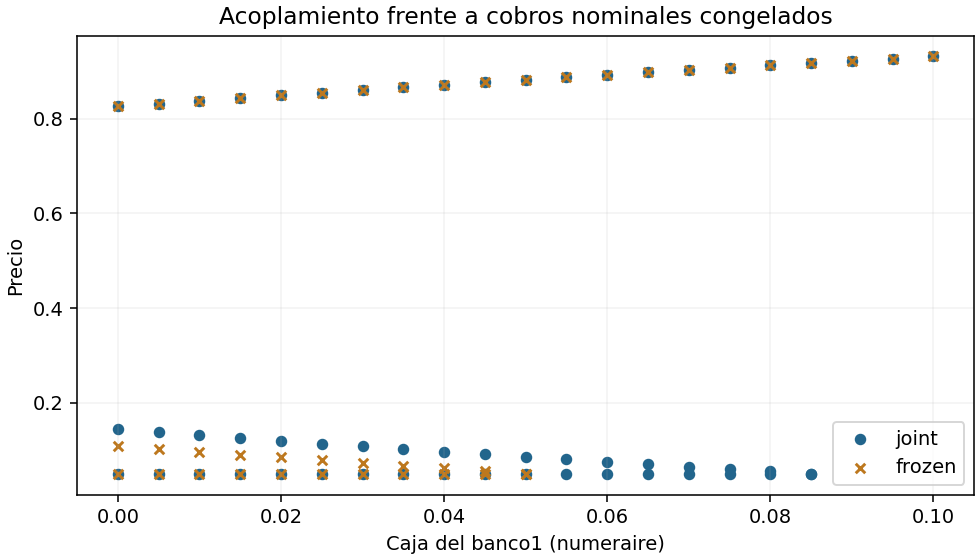

In [4]:
import io
import matplotlib.pyplot as plt
from IPython.display import Image,display
rows=list(csv.DictReader(Path('results/cash_sweep.csv').open()))
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
for label,color,marker in [('joint','#22658c','o'),('frozen','#bd781e','x')]:
 selected=[r for r in rows if r['method']==label]
 ax.scatter([float(r['cash_bank1']) for r in selected],[float(r['price']) for r in selected],color=color,marker=marker,s=24,label=label)
ax.set(xlabel='Caja del banco1 (numeraire)',ylabel='Precio',title='Acoplamiento frente a cobros nominales congelados')
ax.legend();ax.grid(alpha=.15)
buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig)
display(Image(data=buffer.getvalue()))

### Robustez, hipótesis rivales e identificación pendiente
Con impacto cero se recupera EN al precio1. Sin enlaces se recupera el MVP de
ayer. Caja suficiente elimina las ventas, y el ejemplo simétrico conserva los
precios .05,.2,.8. Un pliegue sin enlaces vuelve a revelar el fallo de una malla
basada en cambios de signo: no refuta un teorema de unicidad cuyas hipótesis no
se satisfacen. El modelo tampoco identifica contagio causal observacional:
un factor común puede producir pérdidas simultáneas sin enlaces. Harían falta
balances granulares, exposición predeterminada y un shock exógeno de liquidez
para distinguir esos mecanismos; no se ejecutó ese estudio ni se afirma causalidad.

In [5]:
rng=np.random.default_rng(20261020)
for bump in rng.choice(np.arange(0,8)/100,size=5,replace=False):
 case=replace(e,cash=(float(bump),.02))
 assert census(case)[-1].price>=roots[-1].price-1e-9
print('Cinco perturbaciones deterministas de caja: monotonicidad de la mayor raíz pasa.')
print(Path('results/ablations.csv').read_text())
checks=list(csv.DictReader(Path('results/nested_crosscheck.csv').open()))
print('Contrastes independientes:',len(checks),'máxima diferencia:',max(float(r['max_grid_to_enum_error']) for r in checks))

Cinco perturbaciones deterministas de caja: monotonicidad de la mayor raíz pasa.
case,joint_prices,grid_prices,roots_missed
no_edges,"[0.05, 0.10951650607479953, 0.8255764119219942]","[0.05, 0.10951650607481728, 0.8255764119219943]",0
zero_impact,[1.0],[1.0],0
enough_cash,[1.0],[1.0],0
symmetric,"[0.05, 0.2, 0.8]","[0.05, 0.20000000000000007, 0.8]",0
tangent_no_edges,"[0.05, 0.5]",[0.05],1

Contrastes independientes: 12 máxima diferencia: 2.2426505097428162e-13


### Costos, no superioridad general
La enumeración y la malla buscan múltiples raíces; la iteración superior solo
busca una. No se comparan como tareas equivalentes. Se usa una reducción con
stock y deuda externa agregados constantes para n2/3/4,3 repeticiones.
Se reporta tiempo de pared y pico de asignaciones Python con tracemalloc, no
RSS ni memoria nativa total. La complejidad exponencial impide extrapolar a
128 bancos: se rechaza n>4, no se simula haber validado ese tamaño.

In [6]:
import statistics
rows=list(csv.DictReader(Path('results/costs.csv').open()))
for method in sorted({r['method'] for r in rows}):
 selected=[r for r in rows if r['method']==method and r['n']=='4']
 print(method,'mediana segundos=',statistics.median(float(r['seconds']) for r in selected),'pico Python mediano=',statistics.median(int(r['python_peak_bytes']) for r in selected),'raíces=',selected[0]['roots_recovered']+'/'+selected[0]['reference_roots'])
print(Path('results/coverage.txt').read_text())
print(json.loads(Path('results/metadata.json').read_text()))

nested_grid101 mediana segundos= 0.19354265499987378 pico Python mediano= 9536 raíces= 3/3
regime_census mediana segundos= 0.03804349999995793 pico Python mediano= 30856 raíces= 3/3
upper_nested mediana segundos= 0.026418579999926806 pico Python mediano= 4352 raíces= 1/3
Name             Stmts   Miss Branch BrPart  Cover   Missing
------------------------------------------------------------
src/coupled.py     148      4     64      5    96%   198->202, 218, 227, 230, 233
------------------------------------------------------------
TOTAL              148      4     64      5    96%

{'python': '3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]', 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39', 'cpu': 'INTEL(R) XEON(R) PLATINUM 8573C', 'logical_cpus': 9, 'seed': 20261020, 'base_commit': 'dd5dc42984ca98ecf3ccda47a21dfd4008afe0bb', 'memory': 'Python allocations via tracemalloc, not RSS/native', 'timing': 'wall with tracemalloc,3 paired repeats', 'config_sha256': 'ba7edd1bbaf254ce51ee

## Takeaways y bibliografía
Se cerró un acoplamiento antes pendiente con un caso pequeño ejecutable, no el
programa dinámico completo. Persisten S1:colateral, préstamo, gobierno, feedback
fiscal e identificación. El solver es S2; estos tests no elevan el programa a S3.
Límites:regímenes exponenciales, piso exógeno, precios uniformes y precisión finita.
Fallos corregidos durante desarrollo:imports locales sin excepción E402 y rutas
de lectura iniciales incorrectas al revisar el nuevo auditor estático. No fueron
fallos económicos ni validaciones exitosas. Los resultados guardados corresponden
al pipeline final. Ver informe.md para cobertura medida, fallos y sesgos.
Referencias verificadas: Eisenberg–Noe(2001), DOI10.1287/mnsc.47.2.236.9835;
Feinstein, https://arxiv.org/abs/1506.00937 ; Cifuentes–Ferrucci–Shin,
https://www.bankofengland.co.uk/working-paper/2005/liquidity-risk-and-contagion .
Más fuentes, versiones y enlaces en referencias.bib. No se afirma revisión
exhaustiva ni prioridad científica; bloqueos en results/search_log.md.